# Stroke Prediction: Data Visualization & Preprocessing

## Part 1: Data Loading & Initial Inspection

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

sns.set_style("whitegrid")
df = pd.read_csv("healthcare-dataset-stroke-data.csv")
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [3]:
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


## Part 2: Exploratory Data Analysis & Visualization

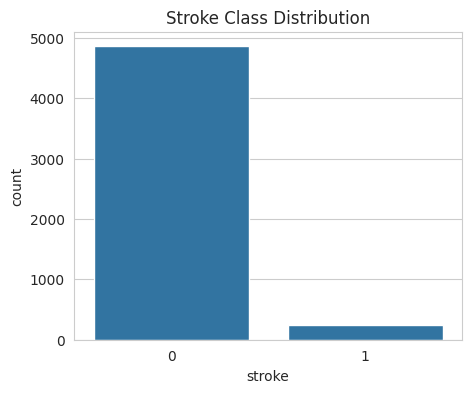

stroke
0    0.951272
1    0.048728
Name: proportion, dtype: float64


In [4]:
# 1. Class distribution
plt.figure(figsize=(5,4))
sns.countplot(x="stroke", data=df)
plt.title("Stroke Class Distribution")
plt.show()
print(df["stroke"].value_counts(normalize=True))

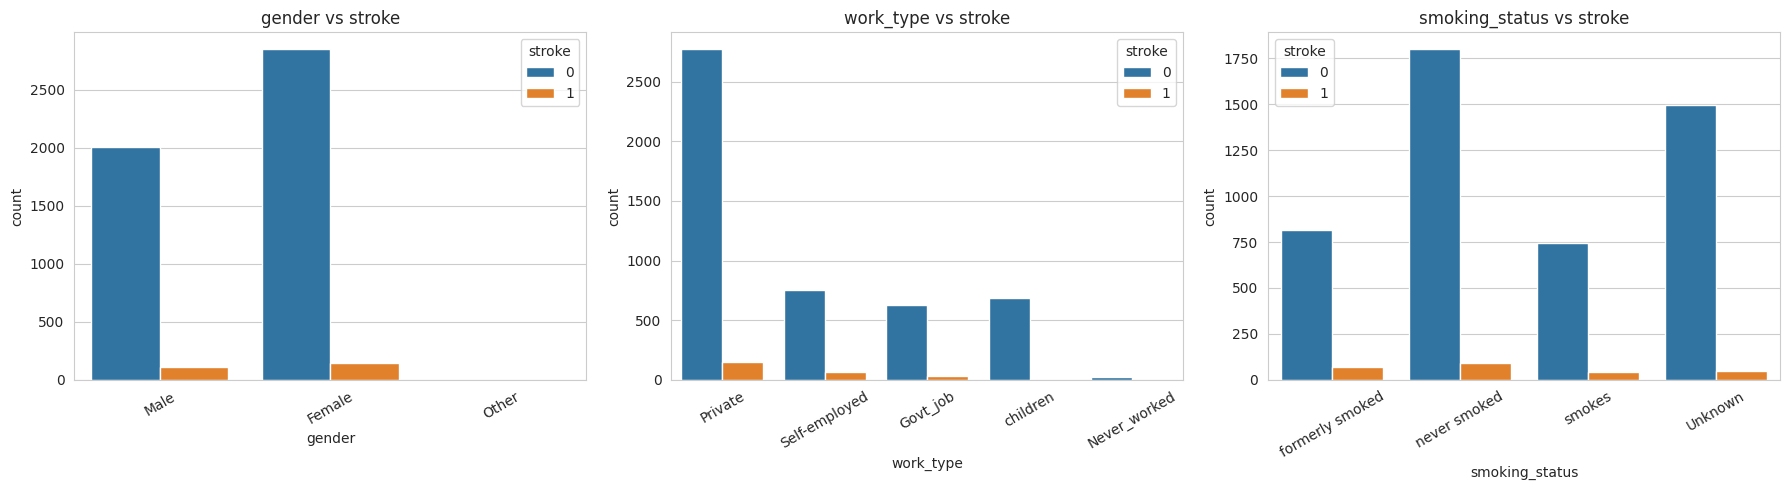

In [5]:
# 2. Categorical features vs stroke
fig, axes = plt.subplots(1, 3, figsize=(18,5))
for ax, col in zip(axes, ["gender", "work_type", "smoking_status"]):
    sns.countplot(x=col, hue="stroke", data=df, ax=ax)
    ax.set_title(f"{col} vs stroke")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

In [6]:
# 3. Drop the single 'Other' gender record
print(df["gender"].value_counts())
df = df[df["gender"] != "Other"]
print(df["gender"].value_counts())

gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64
gender
Female    2994
Male      2115
Name: count, dtype: int64


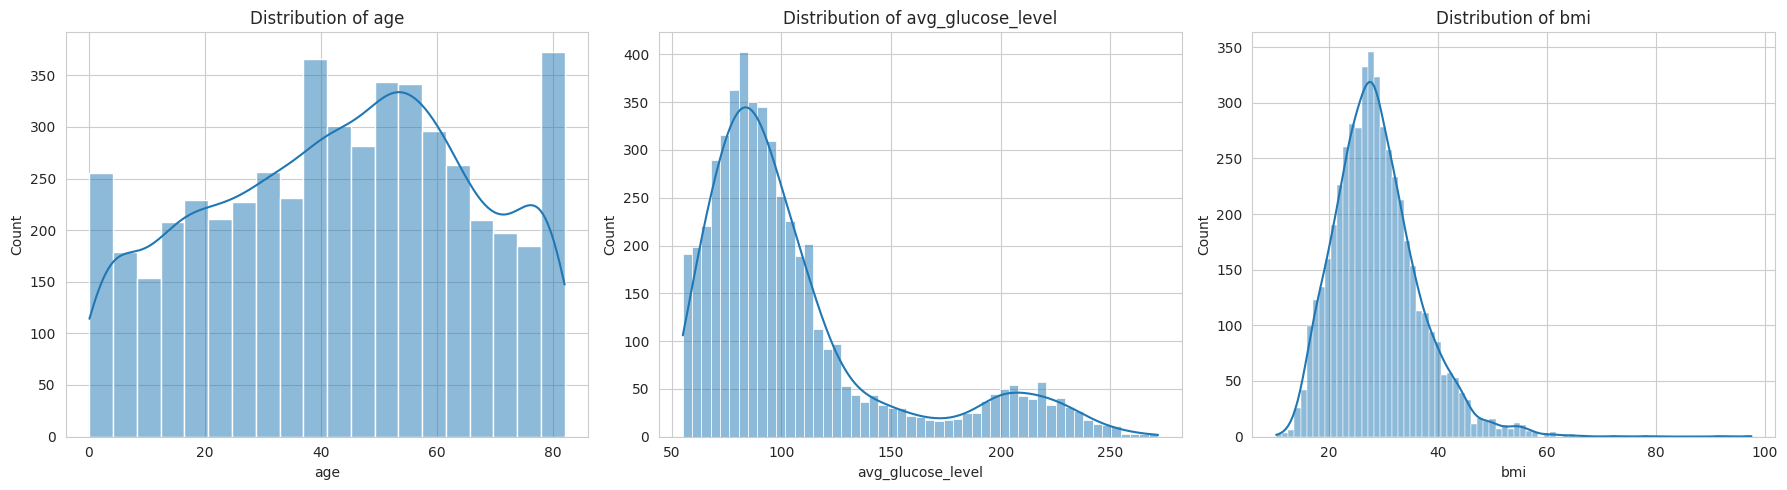

In [7]:
# 4. Distributions of numerical features
fig, axes = plt.subplots(1, 3, figsize=(18,5))
for ax, col in zip(axes, ["age", "avg_glucose_level", "bmi"]):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.show()

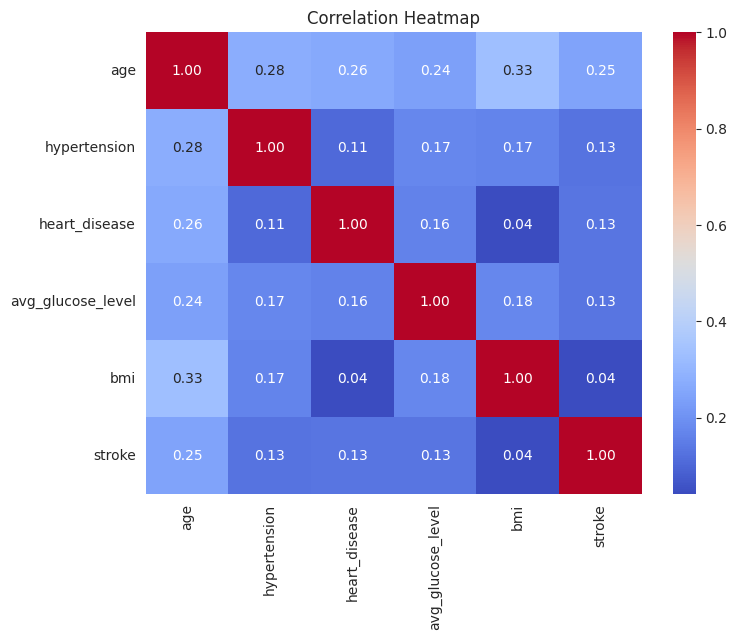

In [8]:
# 5. Correlation heatmap
num_cols = ["age", "hypertension", "heart_disease", "avg_glucose_level", "bmi", "stroke"]
plt.figure(figsize=(8,6))
sns.heatmap(df[num_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

## Part 3: Data Preprocessing (Cleaning)

In [9]:
# 1. Missing values
print(df.isnull().sum())

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64


In [10]:
# 2. Fill bmi with median (robust to outliers, bmi is right-skewed)
df["bmi"] = df["bmi"].fillna(df["bmi"].median())

# 3. Verify
print(df.isnull().sum())

id                   0
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64


In [11]:
# 4. Duplicates
print("Duplicates:", df.duplicated().sum())
df = df.drop_duplicates()

# 5. Drop id
df = df.drop(columns=["id"])
df.shape

Duplicates: 0


(5109, 11)

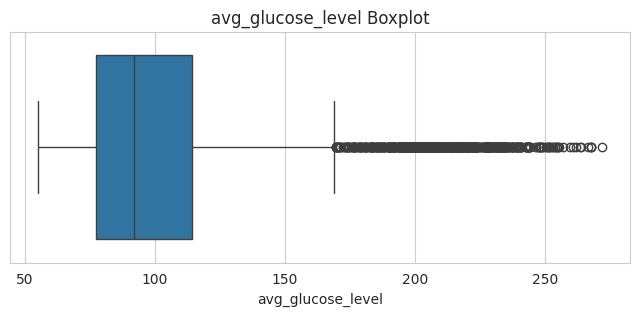

Outliers: 627 | of which stroke = 84


(5109, 11)

In [12]:
# 6. Boxplot for avg_glucose_level
plt.figure(figsize=(8,3))
sns.boxplot(x=df["avg_glucose_level"])
plt.title("avg_glucose_level Boxplot")
plt.show()

Q1, Q3 = df["avg_glucose_level"].quantile([0.25, 0.75])
IQR = Q3 - Q1
lower, upper = Q1 - 1.5*IQR, Q3 + 1.5*IQR
outliers = df[(df["avg_glucose_level"] < lower) | (df["avg_glucose_level"] > upper)]
print("Outliers:", len(outliers), "| of which stroke =", outliers["stroke"].sum())


REMOVE_OUTLIERS = False
if REMOVE_OUTLIERS:
    df = df[(df["avg_glucose_level"] >= lower) & (df["avg_glucose_level"] <= upper)]
df.shape

## Part 4: Feature Transformation

In [13]:
# 1. Binary categorical variables -> 0/1
df["ever_married"] = df["ever_married"].map({"No": 0, "Yes": 1})
df["Residence_type"] = df["Residence_type"].map({"Rural": 0, "Urban": 1})

# 2. Reset index
df = df.reset_index(drop=True)

# 3. One-hot encoding for multi-class categoricals
df = pd.get_dummies(df, columns=["gender", "work_type", "smoking_status"], drop_first=True, dtype=int)
df.head()

,age,hypertension,heart_disease,ever_married,Residence_type,avg_glucose_level,bmi,stroke,gender_Male,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,67.0,0,1,1,1,228.69,36.6,1,1,0,1,0,0,1,0,0
1,61.0,0,0,1,0,202.21,28.1,1,0,0,0,1,0,0,1,0
2,80.0,0,1,1,0,105.92,32.5,1,1,0,1,0,0,0,1,0
3,49.0,0,0,1,1,171.23,34.4,1,0,0,1,0,0,0,0,1
4,79.0,1,0,1,0,174.12,24.0,1,0,0,0,1,0,0,1,0


## Part 5: Data Splitting

In [14]:
X = df.drop(columns=["stroke"])
y = df["stroke"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)

X_train: (4087, 15) | X_test: (1022, 15)
y_train: (4087,) | y_test: (1022,)


## Part 6: Feature Scaling

In [15]:
num_features = ["age", "avg_glucose_level", "bmi"]
scaler = StandardScaler()

X_train[num_features] = scaler.fit_transform(X_train[num_features])
X_test[num_features] = scaler.transform(X_test[num_features])

X_train[num_features].describe().round(2)

,age,avg_glucose_level,bmi
count,4087.00,4087.00,4087.00
mean,-0.00,0.00,-0.00
std,1.00,1.00,1.00
min,-1.91,-1.13,-2.40
25%,-0.81,-0.64,-0.66
50%,0.08,-0.31,-0.10
75%,0.78,0.18,0.51
max,1.71,3.71,8.89


## Part 7: Handling Class Imbalance

In [16]:
# 1. Distribution before
print("Before:\n", y_train.value_counts())

Before:
 stroke
0    3888
1     199
Name: count, dtype: int64


After:
 stroke
0    3888
1    3888
Name: count, dtype: int64


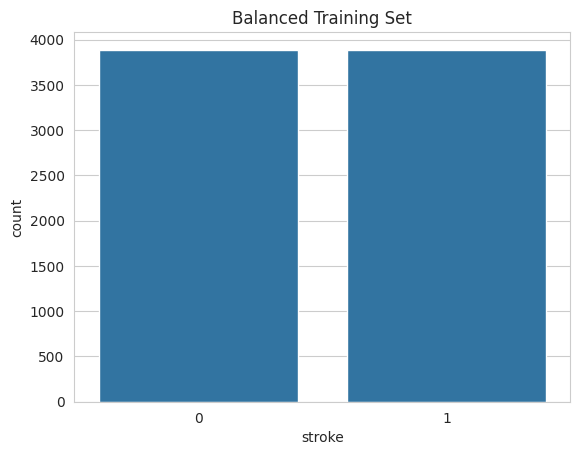

In [17]:
# 2. SMOTE on the training set

from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)

# 3. Verify
print("After:\n", y_train_bal.value_counts())
sns.countplot(x=y_train_bal)
plt.title("Balanced Training Set")
plt.show()

## Conclusion

In this assignment, I cleaned and prepared the stroke dataset for modeling. The dataset has 5,110 patients, and only 4.87% of them had a stroke, so the classes are very imbalanced.

During cleaning, I filled the 201 missing bmi values with the median, removed the one "Other" gender record, and dropped the id column. There were no duplicates. I kept the high glucose values because they are real medical cases, not errors.

The correlation heatmap shows that age has the strongest correlation with stroke (0.25), followed by hypertension, heart disease and average glucose level (0.13 each). BMI has almost no linear correlation with stroke (0.04). All correlations are weak, which suggests stroke risk depends on a combination of factors rather than one feature alone.

After encoding the categorical features, I split the data into 4,087 training rows and 1,022 test rows. I scaled age, avg_glucose_level and bmi using the training data only, so no information leaked from the test set. Then I applied SMOTE on the training set only, which balanced it to 3,888 samples per class.

High-risk patient: an 80-year-old married man, former smoker, with heart disease, average glucose around 200 mg/dL and a BMI above 30. Older age, heart disease, hypertension and high glucose are the main risk factors in this dataset.

The data is now clean, scaled and balanced, and ready for building a classification model.
